# Import Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

PARQUET = "../data/hotspot_indonesia_2012_2026-09.parquet"

df = pd.read_parquet(PARQUET)
df["acq_date"] = pd.to_datetime(df["acq_date"])      # jaga-jaga kalau belum bertipe tanggal

print(f"{len(df):,} baris | {df.shape[1]} kolom")
print(f"Periode: {df['acq_date'].min():%d %b %Y} s/d {df['acq_date'].max():%d %b %Y}")
print()
print("Tipe data:")
print(df.dtypes)
print()
print("Jumlah null per kolom:")
print(df.isna().sum())
print()
print("Jumlah hotspot per tahun:")
print(df["acq_date"].dt.year.value_counts().sort_index())
print()
print("Ringkasan angka (frp, bright_ti4):")
print(df[["frp", "bright_ti4"]].describe())

df.head()

3,941,038 baris | 11 kolom
Periode: 20 Jan 2012 s/d 30 Sep 2026

Tipe data:
latitude             float64
longitude            float64
acq_date      datetime64[ns]
acq_time               int64
confidence            object
frp                  float64
bright_ti4           float64
daynight              object
satellite             object
provinsi              object
produk                object
dtype: object

Jumlah null per kolom:
latitude      0
longitude     0
acq_date      0
acq_time      0
confidence    0
frp           0
bright_ti4    0
daynight      0
satellite     0
provinsi      0
produk        0
dtype: int64

Jumlah hotspot per tahun:
acq_date
2012    317705
2013    256871
2014    551669
2015    874521
2016    116629
2017     90433
2018    192281
2019    436391
2020     92814
2021     70654
2022     63365
2023    249838
2024    115609
2025     94026
2026    418232
Name: count, dtype: int64

Ringkasan angka (frp, bright_ti4):
               frp   bright_ti4
count 3,941,038.00 3,94

,latitude,longitude,acq_date,acq_time,confidence,frp,bright_ti4,daynight,satellite,provinsi,produk
0,-3.84,136.37,2012-01-20,357,n,5.89,333.52,D,SNPP,Papua,VIIRS_SNPP_SP
1,-8.15,125.09,2012-01-20,537,n,5.18,329.62,D,SNPP,NusaTenggaraTimur,VIIRS_SNPP_SP
2,-4.83,122.42,2012-01-20,538,n,2.85,336.13,D,SNPP,SulawesiTenggara,VIIRS_SNPP_SP
3,-4.57,120.16,2012-01-20,538,n,4.17,332.83,D,SNPP,SulawesiSelatan,VIIRS_SNPP_SP
4,-4.57,120.16,2012-01-20,538,n,4.33,332.14,D,SNPP,SulawesiSelatan,VIIRS_SNPP_SP


# Deret waktu hotspot bulanan

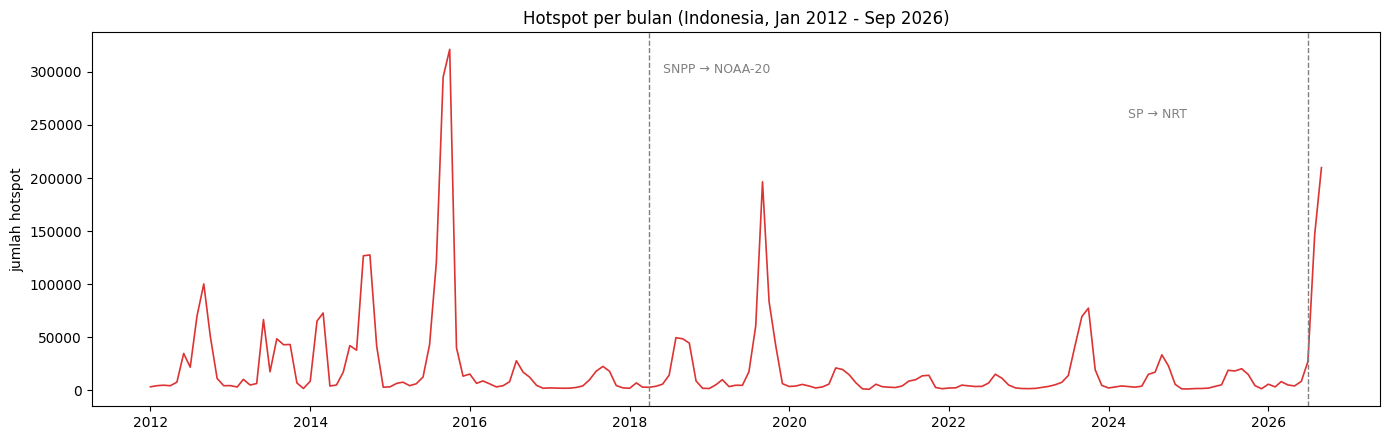

10 bulan tertinggi:
acq_date
2015-10-01    321203
2015-09-01    295182
2026-09-01    209781
2019-09-01    196467
2026-08-01    146440
2014-10-01    127524
2014-09-01    126765
2015-08-01    120760
2012-09-01    100221
2019-10-01     83659
Name: hotspot, dtype: int64

Bulan dengan nilai 0: 0

Bulan yang angkanya persis sama dengan bulan sebelumnya:
Series([], Freq: MS, Name: hotspot, dtype: int64)

2026 per bulan:
acq_date
2026-01-01      5790
2026-02-01      3251
2026-03-01      8209
2026-04-01      5041
2026-05-01      4150
2026-06-01      8474
2026-07-01     27096
2026-08-01    146440
2026-09-01    209781
Freq: MS, Name: hotspot, dtype: int64


In [3]:
bulanan = df.set_index("acq_date").resample("MS").size().rename("hotspot")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(bulanan.index, bulanan.values, color="#d33", lw=1.2)

# penanda perubahan sumber data
ax.axvline(pd.Timestamp("2018-04-01"), color="gray", ls="--", lw=1)
ax.text(pd.Timestamp("2018-06-01"), bulanan.max() * 0.93, "SNPP → NOAA-20", fontsize=9, color="gray")
ax.axvline(pd.Timestamp("2026-07-01"), color="gray", ls="--", lw=1)
ax.text(pd.Timestamp("2024-04-01"), bulanan.max() * 0.80, "SP → NRT", fontsize=9, color="gray")

ax.set_title("Hotspot per bulan (Indonesia, Jan 2012 - Sep 2026)")
ax.set_ylabel("jumlah hotspot")
plt.tight_layout()
plt.show()

print("10 bulan tertinggi:")
print(bulanan.nlargest(10))
print("\nBulan dengan nilai 0:", int((bulanan == 0).sum()))
print("\nBulan yang angkanya persis sama dengan bulan sebelumnya:")
print(bulanan[bulanan.diff() == 0])
print("\n2026 per bulan:")
print(bulanan["2026"])

# heatmap tahun × bulan + cek harian 2018

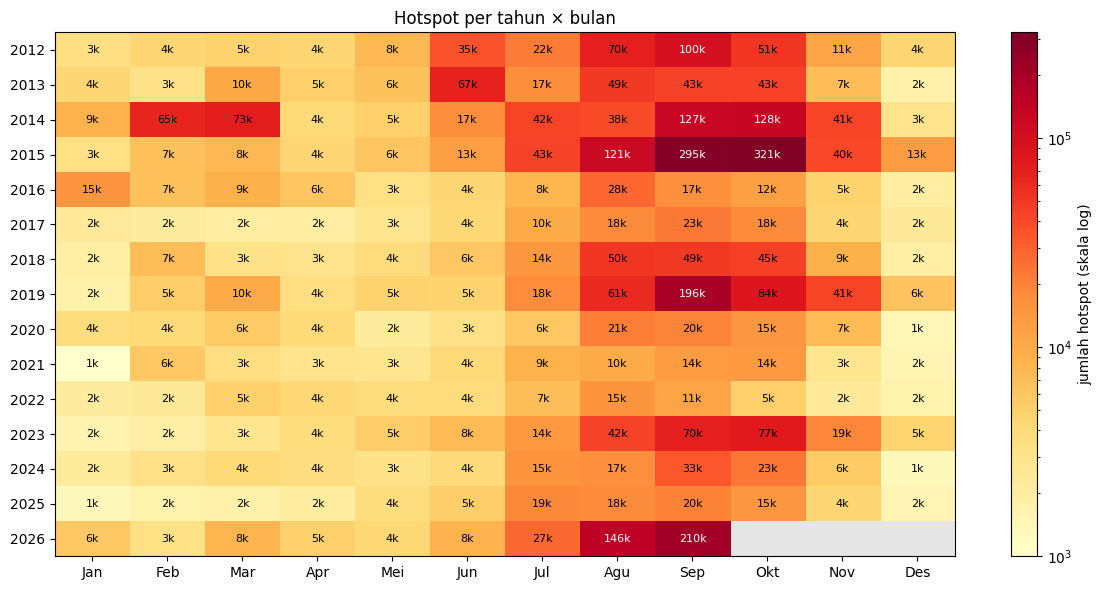

Rata-rata per bulan, semua tahun (ribu):
bulan
1     3.90
2     8.20
3    10.00
4     3.90
5     4.30
6    12.40
7    18.10
8    46.90
9    81.80
10   60.70
11   14.30
12    3.40
dtype: float64

Hari yang punya data: 92 dari 92
count      92.00
mean    1,550.61
std       895.31
min       215.00
25%       821.25
50%     1,285.50
75%     2,169.75
max     3,744.00
dtype: float64

5 hari tertinggi:
acq_date
2018-08-15    3744
2018-08-19    3658
2018-08-18    3525
2018-08-13    3263
2018-09-28    3262
dtype: int64

5 hari terendah:
acq_date
2018-08-01    215
2018-08-02    337
2018-08-03    355
2018-09-06    506
2018-08-04    515
dtype: int64

Bulanan 2018:
bulan
1      1914
2      6994
3      3030
4      2887
5      3808
6      5819
7     14423
8     49604
9     48540
10    44512
11     8825
12     1925
Name: 2018, dtype: int64


In [4]:
import matplotlib.colors as mcolors

# --- Heatmap tahun x bulan ---
pivot = (df.assign(tahun=df["acq_date"].dt.year, bulan=df["acq_date"].dt.month)
           .groupby(["tahun", "bulan"]).size().unstack(fill_value=0))
pivot = pivot.reindex(columns=range(1, 13), fill_value=0)

data = np.ma.masked_equal(pivot.values, 0)            # bulan tanpa data (Okt-Des 2026) abu-abu
cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("#e5e5e5")

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(data, aspect="auto", cmap=cmap,
               norm=mcolors.LogNorm(vmin=1000, vmax=pivot.values.max()))
ax.set_xticks(range(12))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","Mei","Jun","Jul","Agu","Sep","Okt","Nov","Des"])
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(12):
        v = pivot.values[i, j]
        if v > 0:
            ax.text(j, i, f"{v/1000:.0f}k", ha="center", va="center", fontsize=8,
                    color="white" if v > 100_000 else "black")
plt.colorbar(im, label="jumlah hotspot (skala log)")
ax.set_title("Hotspot per tahun × bulan")
plt.tight_layout()
plt.show()

print("Rata-rata per bulan, semua tahun (ribu):")
print((pivot.replace(0, np.nan).mean() / 1000).round(1))

# --- Cek harian Agu-Okt 2018 (curiga data datar/terpotong) ---
h18 = df[(df["acq_date"] >= "2018-08-01") & (df["acq_date"] <= "2018-10-31")]
harian = h18.groupby("acq_date").size()
print("\nHari yang punya data:", len(harian), "dari 92")
print(harian.describe())
print("\n5 hari tertinggi:")
print(harian.nlargest(5))
print("\n5 hari terendah:")
print(harian.nsmallest(5))
print("\nBulanan 2018:")
print(pivot.loc[2018])

# sebaran spasial dan konsentrasi per sel grid

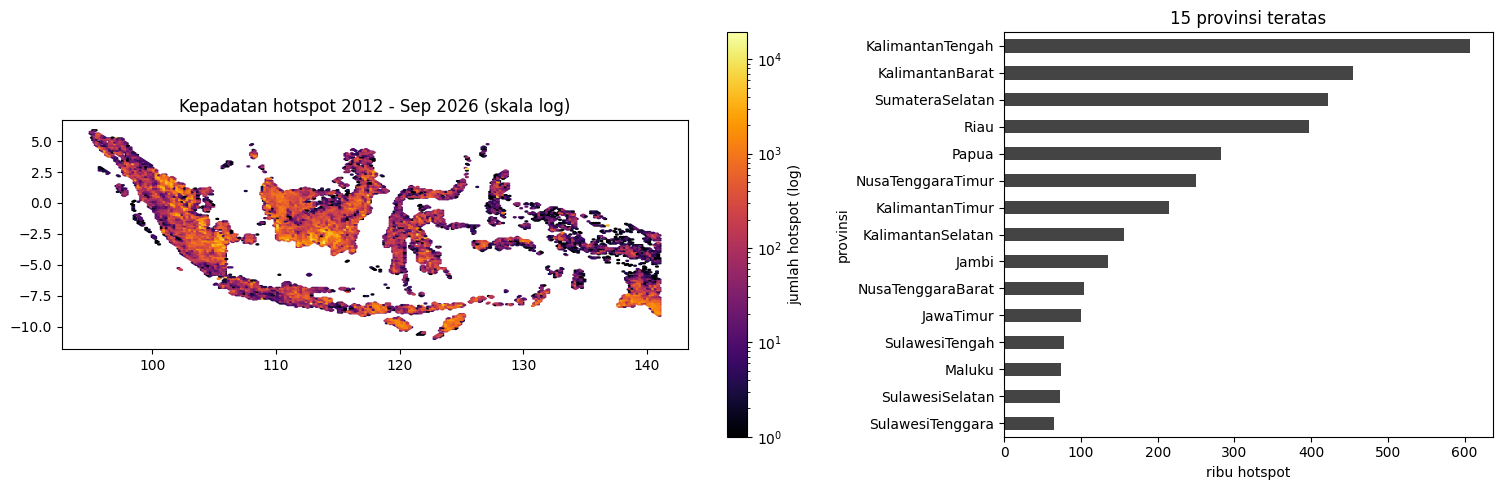

Persentase per pulau:
pulau
Kalimantan             37.10
Sumatera               31.80
Maluku & Papua         10.60
Bali & Nusa Tenggara    9.00
Sulawesi                6.90
Jawa                    4.60
Name: proportion, dtype: float64
Provinsi tak terpetakan: []

Sel 0,25° yang pernah punya hotspot: 3,267
Median hotspot per sel aktif: 368
50% hotspot berasal dari 290 sel (8.9% dari sel aktif)
80% hotspot berasal dari 828 sel (25.3% dari sel aktif)
95% hotspot berasal dari 1,541 sel (47.2% dari sel aktif)

Sel-hari positif: 862,304 dari 17,537,256 (sel aktif × hari) = 4.92%


In [5]:
# --- Provinsi -> pulau ---
PULAU = {
    "Sumatera": ["aceh", "sumatera", "riau", "jambi", "bengkulu", "lampung", "bangka"],
    "Jawa": ["jawa", "banten", "jakarta", "yogyakarta"],
    "Kalimantan": ["kalimantan"],
    "Sulawesi": ["sulawesi", "gorontalo"],
    "Bali & Nusa Tenggara": ["bali", "nusatenggara"],
    "Maluku & Papua": ["maluku", "papua"],
}

def ke_pulau(p):
    p = str(p).lower().replace(" ", "")
    for nama, kunci in PULAU.items():
        if any(k in p for k in kunci):
            return nama
    return "Lainnya"

df["pulau"] = df["provinsi"].map(ke_pulau)

# --- Peta kepadatan + provinsi teratas ---
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})

hb = ax[0].hexbin(df["longitude"], df["latitude"], gridsize=220,
                  bins="log", cmap="inferno", mincnt=1)
ax[0].set_aspect("equal")
ax[0].set_title("Kepadatan hotspot 2012 - Sep 2026 (skala log)")
plt.colorbar(hb, ax=ax[0], label="jumlah hotspot (log)")

top = df["provinsi"].value_counts().head(15)
(top[::-1] / 1000).plot.barh(ax=ax[1], color="#444")
ax[1].set_xlabel("ribu hotspot")
ax[1].set_title("15 provinsi teratas")

plt.tight_layout()
plt.show()

print("Persentase per pulau:")
print((df["pulau"].value_counts(normalize=True) * 100).round(1))
print("Provinsi tak terpetakan:", df.loc[df["pulau"] == "Lainnya", "provinsi"].unique())

# --- Konsentrasi per sel grid 0,25 derajat ---
UKURAN = 0.25
df["lat_i"] = np.floor((df["latitude"] + 12) / UKURAN).astype("int32")
df["lon_i"] = np.floor((df["longitude"] - 94) / UKURAN).astype("int32")
df["sel_id"] = df["lat_i"] * 1000 + df["lon_i"]

per_sel = df["sel_id"].value_counts()
print(f"\nSel 0,25° yang pernah punya hotspot: {len(per_sel):,}")
print(f"Median hotspot per sel aktif: {per_sel.median():.0f}")

kum = per_sel.cumsum() / per_sel.sum()
for p in (0.5, 0.8, 0.95):
    n = int((kum <= p).sum())
    print(f"{p:.0%} hotspot berasal dari {n:,} sel ({n / len(per_sel):.1%} dari sel aktif)")

# --- Seberapa jarang label "ada hotspot" per sel per hari ---
n_hari = (df["acq_date"].max() - df["acq_date"].min()).days + 1
positif = df.groupby(["sel_id", "acq_date"]).ngroups
print(f"\nSel-hari positif: {positif:,} dari {len(per_sel) * n_hari:,} (sel aktif × hari) "
      f"= {positif / (len(per_sel) * n_hari):.2%}")

# confidence, FRP, dan jam rekam (untuk memutuskan batas hari)

Confidence keseluruhan (%):
confidence
n   90.79
l    6.05
h    3.16
Name: proportion, dtype: float64

Confidence per produk (%):
confidence          h    l     n
produk                          
VIIRS_NOAA20_NRT 2.98 5.36 91.66
VIIRS_NOAA20_SP  2.77 6.80 90.42
VIIRS_SNPP_SP    3.42 5.71 90.87

Kuantil frp:
0.00       0.00
0.01       0.49
0.25       2.32
0.50       4.57
0.75       8.45
0.95      25.95
0.99      64.95
1.00     185.07
1.00   1,951.30
Name: frp, dtype: float64
frp == 0: 161

Median frp per confidence:
confidence
h   14.67
l    5.48
n    4.33
Name: frp, dtype: float64

Tanggal lokal (surya) beda dari tanggal UTC: 34.0%
Tanggal WIB beda dari tanggal UTC: 31.1%

Per daynight (surya):
daynight
D   0.00
N   1.00
dtype: float64


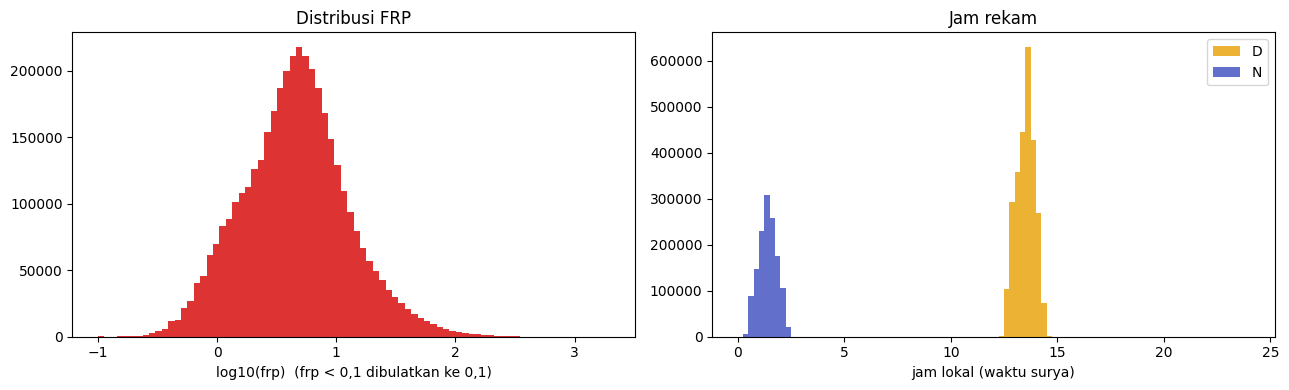

In [6]:
# --- 1. Confidence ---
print("Confidence keseluruhan (%):")
print((df["confidence"].value_counts(normalize=True) * 100).round(2))
print("\nConfidence per produk (%):")
print((pd.crosstab(df["produk"], df["confidence"], normalize="index") * 100).round(2))

# --- 2. FRP ---
print("\nKuantil frp:")
print(df["frp"].quantile([0, .01, .25, .5, .75, .95, .99, .999, 1]).round(2))
print("frp == 0:", int((df["frp"] == 0).sum()))
print("\nMedian frp per confidence:")
print(df.groupby("confidence")["frp"].median().round(2))

# --- 3. Jam rekam dan batas hari ---
jam_utc = df["acq_time"] // 100 + (df["acq_time"] % 100) / 60
jam_lokal = jam_utc + df["longitude"] / 15            # waktu surya lokal
geser = np.floor(jam_lokal / 24).astype(int)           # -1, 0, atau +1 hari terhadap tanggal UTC
jam_lokal = jam_lokal % 24

print("\nTanggal lokal (surya) beda dari tanggal UTC:", f"{(geser != 0).mean():.1%}")
geser_wib = np.floor((jam_utc + 7) / 24).astype(int)
print("Tanggal WIB beda dari tanggal UTC:", f"{(geser_wib != 0).mean():.1%}")
print("\nPer daynight (surya):")
print((geser != 0).groupby(df["daynight"]).mean().round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(np.log10(df["frp"].clip(lower=0.1)), bins=80, color="#d33")
ax[0].set_xlabel("log10(frp)  (frp < 0,1 dibulatkan ke 0,1)")
ax[0].set_title("Distribusi FRP")
for dn, c in [("D", "#e69f00"), ("N", "#3b4cc0")]:
    ax[1].hist(jam_lokal[df["daynight"] == dn], bins=96, range=(0, 24),
               color=c, alpha=0.8, label=dn)
ax[1].set_xlabel("jam lokal (waktu surya)")
ax[1].set_title("Jam rekam")
ax[1].legend()
plt.tight_layout()
plt.show()

# tanggal lokal, matriks sel × hari, dan seberapa kuat “hotspot hari ini” menebak 3 hari ke depan

In [7]:
# --- Tanggal lokal (waktu surya) ---
jam_utc = df["acq_time"] // 100 + (df["acq_time"] % 100) / 60
df["tanggal_lokal"] = (df["acq_date"] + pd.to_timedelta(jam_utc + df["longitude"] / 15, unit="h")).dt.normalize()
print(f"Baris yang tanggalnya bergeser dari UTC: {(df['tanggal_lokal'] != df['acq_date']).mean():.1%}")

# --- Sel grid 0,25 derajat (sama seperti Sel 4) ---
UKURAN = 0.25
df["sel_id"] = (np.floor((df["latitude"] + 12) / UKURAN).astype("int32") * 1000
                + np.floor((df["longitude"] - 94) / UKURAN).astype("int32"))

# --- Buang hari batas yang parsial ---
d = df[(df["tanggal_lokal"] >= "2012-01-21") & (df["tanggal_lokal"] <= "2026-09-30")]
print(f"{len(d):,} baris dipakai ({len(df) - len(d):,} dibuang di hari batas)")

# --- Matriks boolean: sel aktif x hari ---
t0 = d["tanggal_lokal"].min()
n_hari = (d["tanggal_lokal"].max() - t0).days + 1
h = (d["tanggal_lokal"] - t0).dt.days.values
kode, sel_unik = pd.factorize(d["sel_id"])
M = np.zeros((len(sel_unik), n_hari), dtype=bool)
M[kode, h] = True
print(f"Matriks {M.shape[0]:,} sel x {M.shape[1]:,} hari | sel-hari positif: {M.sum():,} ({M.mean():.2%})")

# --- Seberapa kuat hotspot hari ini menebak t+1..t+3? ---
hari_ini = M[:, :-3]
y3 = M[:, 1:-2] | M[:, 2:-1] | M[:, 3:]                 # ada hotspot di t+1, t+2, atau t+3
y1 = M[:, 1:-2]                                          # hanya t+1

print(f"\nLaju dasar y(t+1..t+3)           : {y3.mean():.2%}")
print(f"P(y | ada hotspot hari ini)       : {y3[hari_ini].mean():.1%}")
print(f"P(y | tidak ada hotspot hari ini) : {y3[~hari_ini].mean():.1%}")
print(f"Porsi y=1 yang SUDAH ada hotspot hari ini (recall persistensi): "
      f"{(hari_ini & y3).sum() / y3.sum():.1%}")
print(f"P(t+1 | hari ini)                 : {y1[hari_ini].mean():.1%}")

# --- Laju label per bulan (musiman) ---
tanggal = pd.date_range(t0, periods=n_hari - 3, freq="D")
laju = pd.Series(y3.mean(axis=0), index=tanggal).groupby(tanggal.month).mean()
print("\nLaju y(t+1..t+3) per bulan (% sel aktif):")
print((laju * 100).round(2))

Baris yang tanggalnya bergeser dari UTC: 34.0%
3,938,441 baris dipakai (2,597 dibuang di hari batas)
Matriks 3,266 sel x 5,367 hari | sel-hari positif: 861,825 (4.92%)

Laju dasar y(t+1..t+3)           : 9.91%
P(y | ada hotspot hari ini)       : 62.0%
P(y | tidak ada hotspot hari ini) : 7.2%
Porsi y=1 yang SUDAH ada hotspot hari ini (recall persistensi): 30.7%
P(t+1 | hari ini)                 : 43.1%

Laju y(t+1..t+3) per bulan (% sel aktif):
1     3.83
2     4.79
3     5.22
4     4.59
5     5.38
6     7.92
7    12.55
8    19.88
9    23.74
10   18.93
11    8.39
12    3.37
dtype: float64
